# 00 · Exploración inicial (Hito 1) · Sala de Crisis COVID-19

**Equipo GD 2026-2 · IN1232C**

Notebook del punto de partida sobre los reportes diarios de Johns Hopkins de **enero a
jjunio de 2020**:

1. Cargar `01-22-2020.csv` y describir sus filas, columnas y tipos.
2. Contar nulos por columna e interpretar qué significan.
3. Estandarizar nombres a `snake_case` **en español** y fechas a `AAAA-MM-DD`.
4. Unir enero–junio 2020 en un solo DataFrame.
5. Top 10 países al 30-jun-2020 y evolución de Chile (gráfico de líneas).
6. Perfilado automático y **3 observaciones**.

> Los datos crudos se descargan a `data/raw/` y **no se suben al repositorio**.


In [1]:
import os, sys, time, io, json
import datetime as dt
from pathlib import Path
from urllib.request import urlopen
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 40)
plt.rcParams['figure.figsize'] = (11, 4)

# Rutas: funciona en el repo (notebooks/) y en Colab
PROJECT = Path.cwd()
if not (PROJECT / 'data').exists():
    PROJECT = PROJECT.parent
RAW = PROJECT / 'data' / 'raw' / 'daily_reports'
print('Proyecto:', PROJECT)

Proyecto: C:\Users\hecto\Desktop\Nueva carpeta (2)


## 1 · Cargar el primer reporte: `01-22-2020.csv`

Descarga por URL «raw» de GitHub con caché local (sin clonar el repositorio).

In [2]:
URL_BASE = (
    'https://raw.githubusercontent.com/CSSEGISandData/COVID-19/master/'
    'csse_covid_19_data/csse_covid_19_daily_reports/{nombre}'
)

def descargar(nombre: str) -> bytes:
    '''Descarga un CSV de JHU con caché local (idempotente, con reintentos).'''
    destino = RAW / nombre
    if destino.exists() and destino.stat().st_size > 0:
        return destino.read_bytes()
    RAW.mkdir(parents=True, exist_ok=True)
    for intento in range(3):
        try:
            with urlopen(URL_BASE.format(nombre=nombre), timeout=30) as r:
                datos = r.read()
            if len(datos) < 50:
                raise IOError('respuesta demasiado corta')
            destino.write_bytes(datos)
            return datos
        except Exception:
            if intento == 2:
                raise
            time.sleep(2)

pr1 = pd.read_csv(io.BytesIO(descargar('01-22-2020.csv')))
print('filas:', len(pr1), '| columnas:', len(pr1.columns))

filas: 76 | columnas: 6


In [3]:
pr1.head()

,Province/State,Country/Region,Last Update,Confirmed,Deaths,Recovered
0,Anhui,Mainland China,1/22/2020 17:00,1.0,NaN,NaN
1,Beijing,Mainland China,1/22/2020 17:00,14.0,NaN,NaN
2,Chongqing,Mainland China,1/22/2020 17:00,6.0,NaN,NaN
3,Fujian,Mainland China,1/22/2020 17:00,1.0,NaN,NaN
4,Gansu,Mainland China,1/22/2020 17:00,NaN,NaN,NaN


In [4]:
pr1.shape

(76, 6)

In [5]:
pr1.dtypes

Province/State     object
Country/Region     object
Last Update        object
Confirmed         float64
Deaths            float64
Recovered         float64
dtype: object

## 2 · Nulos por columna y qué significan

En este conjunto los nulos **no son errores de lectura**:

- `Province/State` nulo → el reporte es a nivel país.
- `Deaths` / `Recovered` nulos → la información aún no se reportaba ese día
  (≠ 0 casos).

In [6]:
nulos = pr1.isna().sum().to_frame('nulos')
nulos['% del total'] = (100 * nulos['nulos'] / len(pr1)).round(1)
interpretacion = {
    'Province/State': 'Fila a nivel país (sin provincia/estado)',
    'Confirmed': 'No informado ese día (distinto de 0 casos)',
    'Deaths': 'No informado / aún sin reporte (distinto de 0)',
    'Recovered': 'No informado / aún sin reporte (distinto de 0)',
}
nulos['interpretación'] = [interpretacion.get(c, '—') for c in nulos.index]
nulos

,nulos,% del total,interpretación
Province/State,12,15.8,Fila a nivel país (sin provincia/estado)
Country/Region,0,0.0,—
Last Update,0,0.0,—
Confirmed,10,13.2,No informado ese día (distinto de 0 casos)
Deaths,37,48.7,No informado / aún sin reporte (distinto de 0)
Recovered,37,48.7,No informado / aún sin reporte (distinto de 0)


## 3 · Estandarización: `snake_case` en español y fechas ISO

Mapa único con los nombres originales de JHU → snake_case en español:
`Province/State`→`provincia_estado`, `Country/Region`→`region_pais`,
`Last Update`→`ultima_actualizacion`, `Confirmed`→`confirmados`,
`Deaths`→`fallecidos`, `Recovered`→`recuperados`, `Active`→`activos`,
`Latitude`/`Lat`→`latitud`, `Longitude`/`Long_`→`longitud`,
`Combined_Key`→`clave_combinada`, `Incidence_Rate`/`Incident_Rate`→`tasa_incidentes`,
`Case-Fatality_Ratio`/`Case_Fatality_Ratio`→`tasa_letalidad`.
`fips`, `admin2` y `etapa` se conservan.

In [7]:
MAPA_COLUMNAS = {
    'Province/State': 'provincia_estado', 'Country/Region': 'region_pais',
    'Last Update': 'ultima_actualizacion',
    'Province_State': 'provincia_estado', 'Country_Region': 'region_pais',
    'Last_Update': 'ultima_actualizacion',
    'FIPS': 'fips', 'Admin2': 'admin2',
    'Latitude': 'latitud', 'Longitude': 'longitud', 'Lat': 'latitud', 'Long_': 'longitud',
    'Confirmed': 'confirmados', 'Deaths': 'fallecidos', 'Recovered': 'recuperados',
    'Active': 'activos', 'Combined_Key': 'clave_combinada',
    'Incidence_Rate': 'tasa_incidentes', 'Incident_Rate': 'tasa_incidentes',
    'Case-Fatality_Ratio': 'tasa_letalidad', 'Case_Fatality_Ratio': 'tasa_letalidad',
}

def estandarizar(df: pd.DataFrame) -> pd.DataFrame:
    df = df.rename(columns=MAPA_COLUMNAS)
    s = df['ultima_actualizacion'].astype('string').str.strip()
    fecha = pd.Series(pd.NaT, index=s.index)
    for fmt in ('%m/%d/%y %H:%M', '%m/%d/%Y %H:%M',
                '%m/%d/%y %H:%M:%S', '%m/%d/%Y %H:%M:%S',
                '%Y-%m-%d %H:%M:%S', '%Y-%m-%dT%H:%M:%S', '%Y-%m-%d %H:%M'):
        pend = fecha.isna() & s.notna()
        if pend.any():
            fecha[pend] = pd.to_datetime(s[pend], format=fmt, errors='coerce')
    df['ultima_actualizacion'] = fecha.dt.strftime('%Y-%m-%d')
    return df

pr1_std = estandarizar(pr1)
pr1_std[['provincia_estado', 'region_pais', 'ultima_actualizacion',
         'confirmados', 'fallecidos', 'recuperados']].head()

,provincia_estado,region_pais,ultima_actualizacion,confirmados,fallecidos,recuperados
0,Anhui,Mainland China,2020-01-22,1.0,NaN,NaN
1,Beijing,Mainland China,2020-01-22,14.0,NaN,NaN
2,Chongqing,Mainland China,2020-01-22,6.0,NaN,NaN
3,Fujian,Mainland China,2020-01-22,1.0,NaN,NaN
4,Gansu,Mainland China,2020-01-22,NaN,NaN,NaN


## 4 · Unir enero–junio 2020 en un solo DataFrame

En la ventana hay **tres cambios de esquema**: el **1-mar** se agregan
`Latitude/Longitude` (etapa 2), el **22-mar** pasa a `FIPS, Admin2, Province_State…`
(etapa 3) y el **29-may** se agregan `Incidence_Rate` y `Case-Fatality_Ratio`
(etapa 4). Detectamos la etapa por las columnas presentes y alineamos todo al mapa
estándar. Además:
- guardamos la **fecha del reporte** desde el nombre del archivo (`MM-DD-YYYY.csv`),
  que es la fuente de verdad temporal, y marcamos la **etapa** de cada fila.

In [8]:
def rango_fechas(d1: dt.date, d2: dt.date):
    d = d1
    while d <= d2:
        yield d
        d += dt.timedelta(days=1)

def etapa_parcial(cols) -> int:
    if {'Incidence_Rate', 'Incident_Rate', 'Case_Fatality_Ratio'} & set(cols):
        return 4
    if 'FIPS' in cols:
        return 3
    if 'Latitude' in cols:
        return 2
    return 1

partes = []
for d in rango_fechas(dt.date(2020, 1, 22), dt.date(2020, 6, 30)):
    nombre = f"{d:%m-%d-%Y}.csv"
    try:
        crudo = pd.read_csv(io.BytesIO(descargar(nombre)), low_memory=False)
    except FileNotFoundError:
        print('sin archivo (JHU lo omitió):', nombre)
        continue
    df_dia = estandarizar(crudo)
    df_dia['fecha_reporte'] = f"{d:%Y-%m-%d}"
    df_dia['etapa'] = etapa_parcial(set(crudo.columns))
    partes.append(df_dia)

df = pd.concat(partes, ignore_index=True)
for c in ['confirmados', 'fallecidos', 'recuperados', 'activos', 'latitud',
          'longitud', 'tasa_incidentes', 'tasa_letalidad']:
    if c in df.columns:
        df[c] = pd.to_numeric(df[c], errors='coerce')

print('DataFrame unificado:', df.shape)
print('columnas:', list(df.columns))
print('por etapa →', df['etapa'].value_counts().sort_index().to_dict())

DataFrame unificado: (350945, 16)
columnas: ['provincia_estado', 'region_pais', 'ultima_actualizacion', 'confirmados', 'fallecidos', 'recuperados', 'fecha_reporte', 'etapa', 'latitud', 'longitud', 'fips', 'admin2', 'activos', 'clave_combinada', 'tasa_incidentes', 'tasa_letalidad']
por etapa → {1: 4242, 2: 5555, 3: 217486, 4: 123662}


In [9]:
# ¿qué columna existe desde qué fecha? (insumo del diccionario R2)
extens = {}
for c in ['latitud', 'longitud', 'fips', 'admin2', 'activos', 'clave_combinada',
          'tasa_incidentes', 'tasa_letalidad']:
    v = df.loc[df[c].notna(), 'fecha_reporte'].min()
    extens[c] = f"desde {v}" if pd.notna(v) else 'no aparece en la ventana'
pd.Series(extens).to_frame('primera aparición')

,primera aparición
latitud,desde 2020-03-01
longitud,desde 2020-03-01
fips,desde 2020-03-22
admin2,desde 2020-03-22
activos,desde 2020-03-22
clave_combinada,desde 2020-03-22
tasa_incidentes,desde 2020-05-29
tasa_letalidad,desde 2020-05-29


## 5 · Top 10 países al 30-jun-2020 y evolución de Chile

Cuidado con el doble conteo: hacia el 30-junio Chile ya está por regiones y muchos
países por provincias, así que sumamos por país en la fecha de corte.

In [10]:
top10 = (df.loc[df['fecha_reporte'] == '2020-06-30']
           .groupby('region_pais', as_index=False)['confirmados'].sum()
           .sort_values('confirmados', ascending=False).head(10))
top10

,region_pais,confirmados
183,US,2653658.0
24,Brazil,1412669.0
145,Russia,646929.0
80,India,585493.0
187,United Kingdom,314157.0
139,Peru,285213.0
36,Chile,279393.0
164,Spain,249271.0
86,Italy,240578.0
82,Iran,227662.0


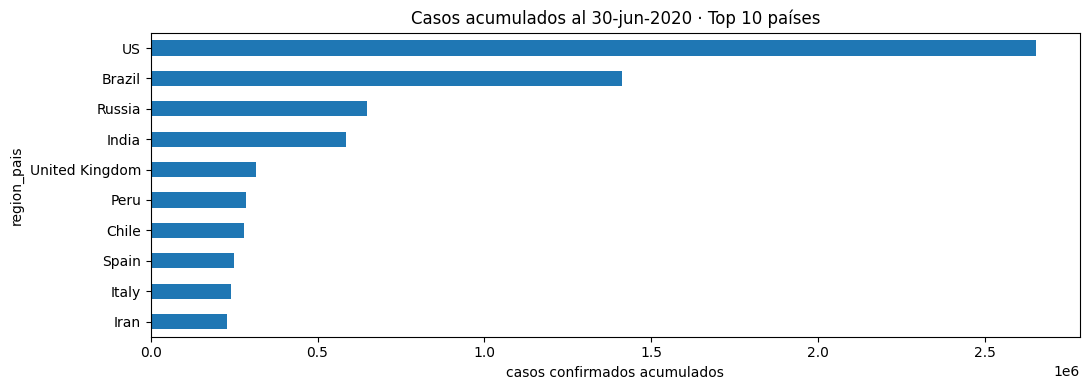

In [11]:
ax = top10.iloc[::-1].plot.barh(x='region_pais', y='confirmados', legend=False,
                                title='Casos acumulados al 30-jun-2020 · Top 10 países')
ax.set_xlabel('casos confirmados acumulados')
plt.tight_layout()
plt.show()

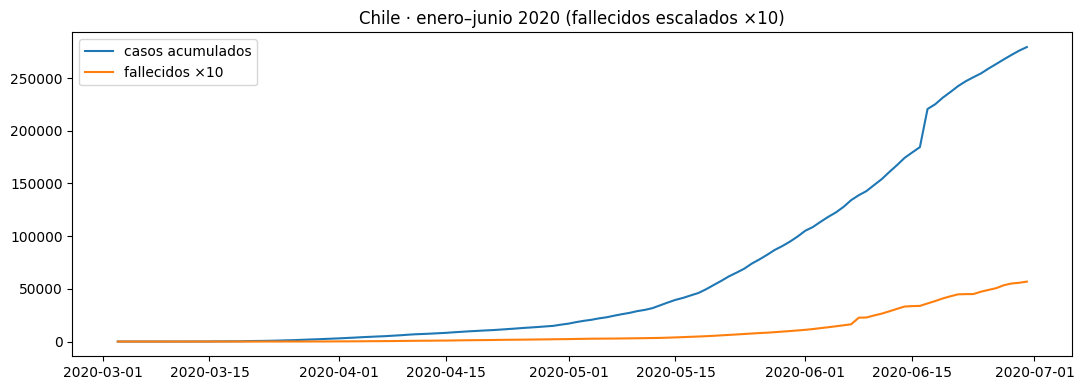

primera fecha con regiones: 2020-05-20 | días con filas regionales: 42 | territorios distintos: 17


In [12]:
chile_linea = (df.loc[df['region_pais'] == 'Chile']
                 .groupby('fecha_reporte', as_index=False)[['confirmados', 'fallecidos']].sum())
chile_linea['fecha_reporte'] = pd.to_datetime(chile_linea['fecha_reporte'])

fig, ax = plt.subplots()
ax.plot(chile_linea['fecha_reporte'], chile_linea['confirmados'], label='casos acumulados')
ax.plot(chile_linea['fecha_reporte'], chile_linea['fallecidos'] * 10, label='fallecidos ×10')
ax.set_title('Chile · enero–junio 2020 (fallecidos escalados ×10)')
ax.legend()
plt.tight_layout()
plt.show()

# el cambio de granularidad es visible: hasta el 19-may Chile es una fila país;
# desde el 20-may son 16 regiones + Unknown (la suma sigue siendo el total del país)
fila_chile = df.loc[df['region_pais'] == 'Chile']
dias = (fila_chile.assign(con_region=fila_chile['provincia_estado'].notna())
                  .groupby('fecha_reporte')['con_region'].sum())
print('primera fecha con regiones:', dias[dias > 0].index.min(),
      '| días con filas regionales:', int((dias > 0).sum()),
      '| territorios distintos:', fila_chile['provincia_estado'].nunique())

## 6 · Perfilado automático y observaciones

Usamos `fg-data-profiling` (paquete vigente); si no está instalado, `ydata-profiling`.
El reporte HTML se guarda en `data/profile/` (no se sube al repo).

In [13]:
salida = PROJECT / 'data' / 'profile'
salida.mkdir(parents=True, exist_ok=True)

# paquete vigente: fg-data-profiling; respaldo: ydata-profiling
ProfileReport = None
try:
    from data_profiling import ProfileReport
except ImportError:
    try:
        from ydata_profiling import ProfileReport
    except ImportError:
        pass

if ProfileReport is not None:
    perfil = ProfileReport(df, title='COVID-19 · enero-junio 2020',
                           minimal=True, progress_bar=False)
    perfil.to_file(salida / 'perfilado_exploracion.html')
    print('Reporte completo →', (salida / 'perfilado_exploracion.html').resolve())
else:
    print('Sin librería de perfilado instalada → resumen manual')

# el grano real es territorio × día: país + provincia + condado (admin2, EE.UU.)
llave = ['fecha_reporte', 'provincia_estado', 'region_pais', 'admin2']
resumen = pd.DataFrame({
    'valor': [
        f'{len(df):,}',
        str(df.shape[1]),
        f'{int(df.duplicated(subset=llave).sum()):,}',
        f'{df.isna().mean().mean() * 100:.2f}%',
        f'{int(df.duplicated().sum()):,}',
    ]}, index=['filas', 'columnas', 'duplicados (llave completa)', '% celdas nulas',
               'filas duplicadas exactas'])
resumen

  0%|          | 0/16 [00:00<?, ?it/s]

  6%|▋         | 1/16 [00:00<00:06,  2.18it/s]

 25%|██▌       | 4/16 [00:00<00:02,  4.29it/s]

 31%|███▏      | 5/16 [00:01<00:02,  4.77it/s]

 56%|█████▋    | 9/16 [00:02<00:01,  4.60it/s]

 62%|██████▎   | 10/16 [00:02<00:01,  4.44it/s]

 69%|██████▉   | 11/16 [00:02<00:01,  4.88it/s]

 81%|████████▏ | 13/16 [00:03<00:00,  3.24it/s]

100%|██████████| 16/16 [00:03<00:00,  4.69it/s]

Reporte completo → C:\Users\hecto\Desktop\Nueva carpeta (2)\data\profile\perfilado_exploracion.html


,valor
filas,"350,945"
columnas,16
duplicados (llave completa),3
% celdas nulas,11.28%
filas duplicadas exactas,1


In [14]:
pd.DataFrame({
    'tipo': df.dtypes.astype(str),
    'nulos': df.isna().sum(),
    '% nulos': (df.isna().mean() * 100).round(1),
    'únicos': df.nunique(dropna=True),
})

,tipo,nulos,% nulos,únicos
provincia_estado,object,22249,6.3,730
region_pais,object,0,0.0,246
ultima_actualizacion,object,0,0.0,163
confirmados,float64,28,0.0,15173
fallecidos,float64,432,0.1,3806
recuperados,float64,385,0.1,7853
fecha_reporte,object,0,0.0,161
etapa,int64,0,0.0,4
latitud,float64,10694,3.0,4276
longitud,float64,10694,3.0,4306


### Tres observaciones del perfilado

1. **La cobertura de columnas crece con el tiempo y no es homogénea.** `latitud`/
   `longitud` no existen antes del 1-mar-2020; `fips`, `admin2`, `activos` y
   `clave_combinada` aparecen el 22-mar-2020; `tasa_incidentes` y `tasa_letalidad`, el
   29-may-2020. Cualquier análisis que use esas columnas debe recortar su ventana: no son
   «nulos» aleatorios, son **columnas que aún no existían**.
2. **Gran parte de los nulos es informativa, no ruido.** En el primer reporte (22-ene),
   el 48,7% de `fallecidos` y `recuperados` son nulos porque aún no se reportaban; en
   toda la ventana el 11,28% de las celdas está nulo. `provincia_estado` nulo significa
   «fila a nivel país» y `admin2` nulo, «fuera de EE.UU.». Imputar esos valores sería
   inventar información: se marcan y se documentan.
3. **El grano real es territorio × día, y la llave debe incluir `admin2`.** Con la llave
   país + provincia, 291.074 filas «parecen» duplicadas; al agregar `admin2` quedan solo
   3 duplicados (y 1 fila exactamente idéntica) en 350.945 filas. Además,
   `ultima_actualizacion` no es la fecha del reporte (trae horas y zonas horarias): el
   grano temporal es `fecha_reporte`, tomado del nombre del archivo.


## Conclusiones y puente al Hito 2

- **Chile cierra junio como 7.º del mundo en casos acumulados (279.393), detrás de
  EE.UU. (2.653.658), Brasil, Rusia, India, Reino Unido y Perú.** El ranking mezcla
  tamaño poblacional: por eso el análisis (R4) usará tasas por 100.000.
- Los cambios de esquema se resuelven con **un mapa único de columnas**, no con parches
  por archivo: esa función ya es la semilla de la capa limpia (R1).
- Los **acumulados** dominan: los casos/fallecidos nuevos se calcularán en el Hito 2 y
  habrá días en que el acumulado **baje** (correcciones); se registrarán, no se borrarán.
- El cambio de granularidad de **Chile (país → 16 regiones + Unknown)** obliga a un
  control por fecha y nivel territorial (verificado en la celda anterior).
- Siguiente paso (Hito 2): descargar los **1.143 reportes**, capa Parquet, reglas de
  calidad por las 6 dimensiones y modelo en estrella en DuckDB.
